# Informe de evaluación de modelos
## Detección de burnout alto en desarrolladores
**Estudiante:** Daiana Sepúlveda  
**Pre-entrega:** Evaluación y comparación del pipeline

## 1. Datos y preparación
Mantuve los filtros de la entrega anterior: horas de trabajo mayores que cero, estrés mayor o igual a cero y una diferencia de al menos 18 años entre la edad y la experiencia laboral. También eliminé los registros duplicados y los que no tenían un nivel de burnout válido.

Agrupé los niveles de burnout en dos categorías: alto (1) y bajo o medio (0). Así, los modelos buscan identificar los casos de burnout alto.

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, average_precision_score)


url = 'https://raw.githubusercontent.com/DaianaSep/pre-entrega-7/refs/heads/main/developer_burnout_dataset_7000.csv'
df = pd.read_csv(url)
filtro = ((df.daily_work_hours > 0) & (df.stress_level >= 0)
          & ((df.age - df.experience_years) >= 18))
datos = df.loc[filtro].drop_duplicates().copy()
datos = datos[datos.burnout_level.isin(['Low', 'Medium', 'High'])].copy()
X = datos.drop(columns='burnout_level')
y = (datos.burnout_level == 'High').astype(int)
print(f'Registros originales: {len(df)} | Registros utilizados: {len(datos)}')
display(pd.DataFrame({'Cantidad': y.value_counts().sort_index(),
                      'Porcentaje': y.value_counts(normalize=True).sort_index().mul(100)})
        .rename(index={0: 'Bajo o medio (0)', 1: 'Alto (1)'}).round(2))

Registros originales: 7000 | Registros utilizados: 4444


,Cantidad,Porcentaje
burnout_level,,
Bajo o medio (0),3273,73.65
Alto (1),1171,26.35


## 2. Entrenamiento comparativo
Dividí los datos en dos partes: el 80 % para entrenar los modelos y el 20 % para probarlos. Usé los mismos datos en ambos modelos para poder comparar sus resultados.

Completé los valores faltantes con la mediana y ajusté la escala de las variables para la regresión logística. Para estos pasos usé solo los datos de entrenamiento.

Comparé regresión logística con random forest, con 200 árboles. En ambos tuve en cuenta que hay menos casos de burnout alto, dándoles más peso durante el entrenamiento. Dejé las configuraciones fijas y usé los datos de prueba para evaluar cómo funcionó cada modelo.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
modelos = {
    'Regresión Logística': Pipeline([
        ('imputacion', SimpleImputer(strategy='median')),
        ('escalado', StandardScaler()),
        ('modelo', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))]),
    'Random Forest': Pipeline([
        ('imputacion', SimpleImputer(strategy='median')),
        ('modelo', RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                          random_state=42, n_jobs=-1))])
}
predicciones, probabilidades, filas = {}, {}, []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones[nombre] = modelo.predict(X_test)
    probabilidades[nombre] = modelo.predict_proba(X_test)[:, 1]
    filas.append({'Modelo': nombre,
                  'Precision': precision_score(y_test, predicciones[nombre], zero_division=0),
                  'Recall': recall_score(y_test, predicciones[nombre], zero_division=0),
                  'F1-Score': f1_score(y_test, predicciones[nombre], zero_division=0),
                  'AUC-ROC': roc_auc_score(y_test, probabilidades[nombre])})
resultados = pd.DataFrame(filas).set_index('Modelo')
print(f'Entrenamiento: {len(y_train)} | Prueba: {len(y_test)}')
display(resultados.round(4))

Entrenamiento: 3555 | Prueba: 889


,Precision,Recall,F1-Score,AUC-ROC
Modelo,,,,
Regresión Logística,0.9213,1.0000,0.9590,0.9996
Random Forest,1.0000,0.9957,0.9979,1.0000


## 3. Matrices de confusión
Las filas muestran el nivel de burnout que figura en los datos y las columnas lo que predijo el modelo. Un falso negativo ocurre cuando el caso tiene burnout alto, pero el modelo lo marca como bajo o medio. Un falso positivo es lo contrario: el modelo marca burnout alto cuando en los datos aparece como bajo o medio.

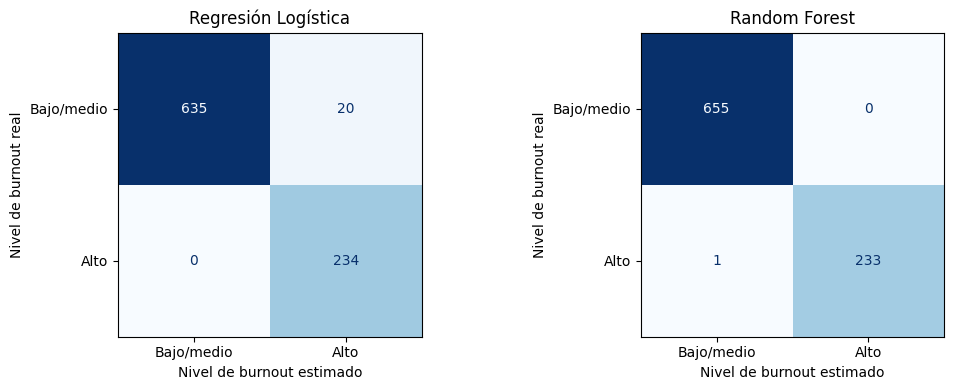

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nombre, pred) in zip(axes, predicciones.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1],
        display_labels=['Bajo/medio', 'Alto'], cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel('Nivel de burnout estimado')
    ax.set_ylabel('Nivel de burnout real')
plt.tight_layout()
plt.show()

## 4. Curvas ROC comparadas
El eje horizontal representa la tasa de falsos positivos y el vertical la tasa de verdaderos positivos (recall)

El AUC indica qué tan bien el modelo distingue los casos de burnout alto de los bajos o medios. Un valor de 0,5 equivale a hacerlo al azar y un valor de 1 indica que los distingue perfectamente en los datos evaluados. No es el porcentaje de aciertos del modelo.

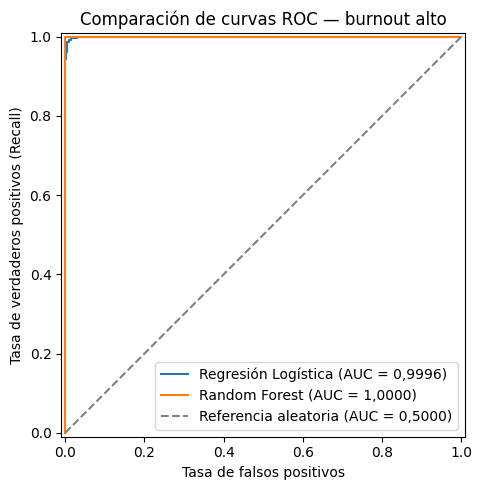

Regresión Logística: AUC = 0.9996.
Random Forest: AUC = 1.0000.


In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, prob in probabilidades.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=nombre, ax=ax)
    auc_texto = f'{roc_auc_score(y_test, prob):.4f}'.replace('.', ',')
    ax.lines[-1].set_label(f'{nombre} (AUC = {auc_texto})')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Referencia aleatoria (AUC = 0,5000)')
ax.set(title='Comparación de curvas ROC — burnout alto',
       xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos (Recall)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()
for nombre, fila in resultados.iterrows():
    print(f'{nombre}: AUC = {fila["AUC-ROC"]:.4f}.')

### Precision-Recall
Esta curva permite observar el equilibrio entre la confiabilidad de las alertas (precisión) y la proporción de casos altos detectados (recall), especialmente útil cuando existe desbalance. La línea horizontal indica la proporción de positivos en test. AP resume la curva; no reemplaza el F1 al umbral elegido.

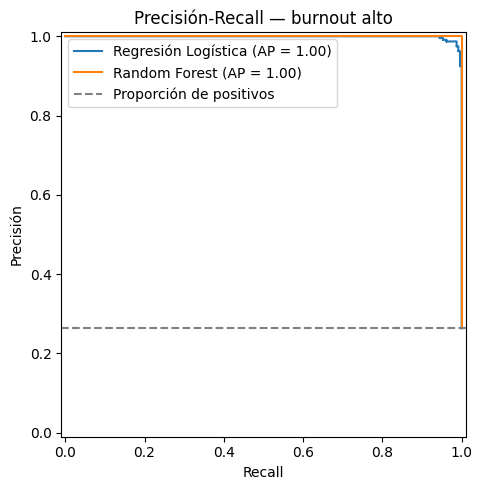

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, prob in probabilidades.items():
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=nombre, ax=ax)
ax.axhline(y_test.mean(), linestyle='--', color='gray', label='Proporción de positivos')
ax.set(title='Precisión-Recall — burnout alto', xlabel='Recall', ylabel='Precisión')
ax.legend(loc='best')
plt.tight_layout()
plt.show()

## 5. Conclusión técnica y de negocio
La **precision** expresa qué proporción de las alertas corresponde a burnout alto. El **recall** expresa qué proporción de los casos altos se detecta. El **F1-Score** resume su equilibrio; por eso la selección no se basa solo en accuracy ni en pequeñas diferencias de AUC.

Para una alerta preventiva, se considera más crítico el falso negativo: omitir un caso alto puede retrasar una intervención de apoyo. Los falsos positivos también tienen costo, porque requieren revisión y pueden generar alertas innecesarias. Se recomienda el modelo con mayor F1 en esta comparación, revisando explícitamente su recall y sus errores antes de considerar su implementación.

In [ ]:
elegido = resultados.sort_values(['F1-Score', 'Recall'], ascending=False).index[0]
r = resultados.loc[elegido]
from sklearn.metrics import confusion_matrix
vn, fp, fn, vp = confusion_matrix(y_test, predicciones[elegido], labels=[0, 1]).ravel()
display(Markdown(
    f'**Recomendación: {elegido}.** En el conjunto de prueba obtuvo '
    f'precision **{r["Precision"]:.3f}**, recall **{r["Recall"]:.3f}**, '
    f'F1 **{r["F1-Score"]:.3f}** y AUC **{r["AUC-ROC"]:.3f}**. '
    f'Detectó **{vp} de {vp + fn}** casos de burnout alto, '
    f'con **{fn} falsos negativos** y **{fp} falsos positivos**. '
    'La recomendación se limita a esta muestra y a una alerta con revisión humana. '
    'Antes de implementarlo, sería necesario validar con datos nuevos y confirmar '
    'cómo se construyó la etiqueta de burnout, especialmente su relación con el estrés.'))

**Recomendación: Random Forest.** En el conjunto de prueba obtuvo precision **1.000**, recall **0.996**, F1 **0.998** y AUC **1.000**. Detectó **233 de 234** casos de burnout alto, con **1 falsos negativos** y **0 falsos positivos**. La recomendación se limita a esta muestra y a una alerta con revisión humana. Antes de implementarlo, sería necesario validar con datos nuevos y confirmar cómo se construyó la etiqueta de burnout, especialmente su relación con el estrés.

**Lectura de los resultados obtenidos:** Random Forest obtuvo precision de 1,0000, recall de 0,9957 y F1 de 0,9979. Detectó 233 de los 234 casos altos: tuvo 1 falso negativo y ningún falso positivo. Regresión Logística detectó los 234 casos altos, pero generó 20 falsos positivos; obtuvo precision de 0,9213, recall de 1,0000 y F1 de 0,9590.

Recomendaría Random Forest por su mejor equilibrio entre precision y recall. Sin embargo, dejó sin detectar un caso alto. Si la prioridad fuera no omitir ningún caso, elegiría Regresión Logística con estas configuraciones.

Los resultados corresponden a este test y no garantizan el mismo desempeño con datos nuevos. Un AUC de 1 no significa que todas las predicciones sean correctas con el umbral utilizado. Antes de implementarlo, revisaría cómo se construyó la etiqueta de burnout y su relación con el estrés.